## Import libraries

In [1]:
import pandas as pd
import numpy as np
import duckdb

import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score
)

Define project paths

In [2]:
INTEGRATED_DIR = Path("../outputs/integrated_data")

customer_features_path = (
    INTEGRATED_DIR / "customer_features.parquet"
).resolve()

print("File exists:", customer_features_path.exists())

File exists: True


### Load customer features

inspecting data from ccustomer_features.parquet file

In [3]:
customer_df = pd.read_parquet(customer_features_path)

print("Dataset shape:", customer_df.shape)

display(customer_df.head())

Dataset shape: (206209, 3)


,user_id,total_previous_orders,avg_basket_size
0,116348,6,10.833333
1,163596,21,9.714286
2,39668,29,9.000000
3,177568,9,15.333333
4,84100,10,21.600000


## Customer feature engineering
We'll create these five customer behaviour features:

total_previous_orders :	Total number of previous orders

avg_basket_size	: Average products purchased per order

avg_days_between_orders : 	Average time between orders

unique_products	: Number of different products purchased

reorder_rate :	Proportion of purchases that were reorders

Define paths and connect DuckDB

In [5]:
CLEAN_DIR = Path("../outputs/cleaned_data")

orders_path = (CLEAN_DIR / "orders.csv").resolve().as_posix()

integrated_path = (
    INTEGRATED_DIR / "integrated_prior.parquet"
).resolve().as_posix()

con = duckdb.connect()

print("Orders file exists:", Path(orders_path).exists())
print("Integrated file exists:", Path(integrated_path).exists())

Orders file exists: True
Integrated file exists: True


### Feature engineering query

In [8]:
advanced_features_path = (
    INTEGRATED_DIR / "advanced_customer_features.parquet"
).resolve().as_posix()

con.execute(f"""
COPY (
    WITH product_stats AS (
        SELECT
            user_id,
            COUNT(DISTINCT product_id) AS unique_products,
            AVG(reordered) AS reorder_rate
        FROM read_parquet('{integrated_path}')
        GROUP BY user_id
    ),

    order_intervals AS (
        SELECT
            user_id,
            AVG(days_since_prior_order) AS avg_days_between_orders
        FROM read_csv_auto('{orders_path}')
        WHERE eval_set = 'prior'
          AND days_since_prior_order IS NOT NULL
        GROUP BY user_id
    )

    SELECT
        c.user_id,
        c.total_previous_orders,
        c.avg_basket_size,
        o.avg_days_between_orders,
        p.unique_products,
        p.reorder_rate

    FROM read_parquet('{customer_features_path}') c

    LEFT JOIN product_stats p
        ON c.user_id = p.user_id

    LEFT JOIN order_intervals o
        ON c.user_id = o.user_id

)
TO '{advanced_features_path}'
(FORMAT PARQUET, COMPRESSION ZSTD)
""")

print("Advanced customer features created!")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Advanced customer features created!


Load and verify

In [10]:
customer_df = pd.read_parquet(advanced_features_path)

print("Dataset shape:", customer_df.shape)
display(customer_df.head())

Dataset shape: (206209, 6)


,user_id,total_previous_orders,avg_basket_size,avg_days_between_orders,unique_products,reorder_rate
0,55122,38,1.894737,6.945946,11,0.847222
1,121486,44,12.727273,8.255814,181,0.676786
2,115925,99,8.121212,3.622449,305,0.620647
3,165365,82,8.609756,4.469136,192,0.728045
4,33399,47,6.680851,7.695652,59,0.812102


#### Separate features from the user ID

user_id is an identifier, not a behavioural feature. We should not use it for clustering.

In [12]:
# Remove user_id from clustering features
X = customer_df.drop(columns=["user_id"])

# Check the features
print(X.head())
print("\nDataset shape:", X.shape)

   total_previous_orders  avg_basket_size  avg_days_between_orders  \
0                     38         1.894737                 6.945946   
1                     44        12.727273                 8.255814   
2                     99         8.121212                 3.622449   
3                     82         8.609756                 4.469136   
4                     47         6.680851                 7.695652   

   unique_products  reorder_rate  
0               11      0.847222  
1              181      0.676786  
2              305      0.620647  
3              192      0.728045  
4               59      0.812102  

Dataset shape: (206209, 5)


### Feature Scaling (Standardization)

In [13]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Original shape:", X.shape)
print("Scaled shape:", X_scaled.shape)

Original shape: (206209, 5)
Scaled shape: (206209, 5)


In [14]:
print("Mean:")
print(X_scaled.mean(axis=0).round(2))

print("\nStandard Deviation:")
print(X_scaled.std(axis=0).round(2))

Mean:
[-0.  0. -0. -0. -0.]

Standard Deviation:
[1. 1. 1. 1. 1.]


## K-Means Clustering

In [16]:
inertia_values = []

for k in range(2, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled)

    inertia_values.append(kmeans.inertia_)

print(inertia_values)

#Trying cluster counts from 2 to 10.

#Training a K-Means model for each count.

#Recording its inertia (within-cluster sum of squared distances).

[680699.3530807189, 557754.625847689, 455418.51187791943, 399977.08237061277, 363249.6351582913, 332729.6680871545, 308464.7493492839, 286658.0984929241, 268337.63601304125]


Plot the Elbow Curve

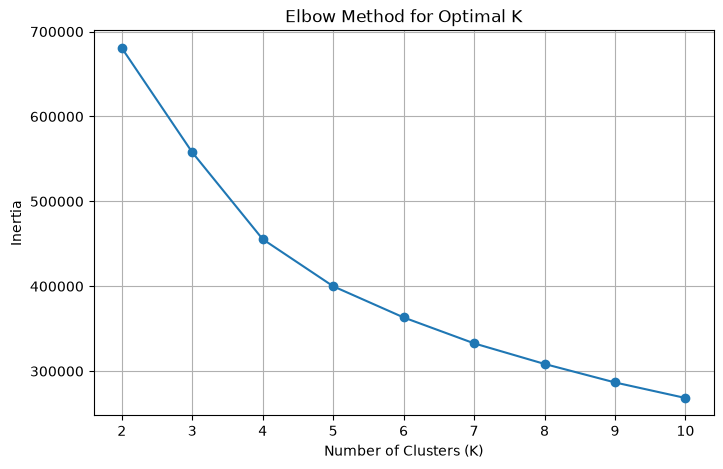

In [17]:
plt.figure(figsize=(8, 5))

plt.plot(range(2, 11), inertia_values, marker='o')

plt.title("Elbow Method for Optimal K")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.xticks(range(2, 11))
plt.grid(True)

plt.show()

### Train the K-Means model

In [18]:
kmeans_model = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

# Assign each customer to a cluster
customer_df["KMeans_Cluster"] = kmeans_model.fit_predict(X_scaled)

print(customer_df.head())

   user_id  total_previous_orders  avg_basket_size  avg_days_between_orders  \
0    55122                     38         1.894737                 6.945946   
1   121486                     44        12.727273                 8.255814   
2   115925                     99         8.121212                 3.622449   
3   165365                     82         8.609756                 4.469136   
4    33399                     47         6.680851                 7.695652   

   unique_products  reorder_rate  KMeans_Cluster  
0               11      0.847222               0  
1              181      0.676786               3  
2              305      0.620647               3  
3              192      0.728045               3  
4               59      0.812102               3  


Customers distribution

In [19]:
cluster_counts = customer_df["KMeans_Cluster"].value_counts().sort_index()

print(cluster_counts)

KMeans_Cluster
0    69914
1    39085
2    71365
3    25845
Name: count, dtype: int64


In [20]:
cluster_summary = customer_df.groupby("KMeans_Cluster")[
    [
        "total_previous_orders",
        "avg_basket_size",
        "avg_days_between_orders",
        "unique_products",
        "reorder_rate"
    ]
].mean().round(2)

display(cluster_summary)

,total_previous_orders,avg_basket_size,avg_days_between_orders,unique_products,reorder_rate
KMeans_Cluster,,,,,
0,15.22,7.11,11.36,46.33,0.51
1,11.17,18.07,15.94,94.08,0.45
2,5.72,7.63,21.54,30.85,0.25
3,50.54,11.77,7.06,162.14,0.68


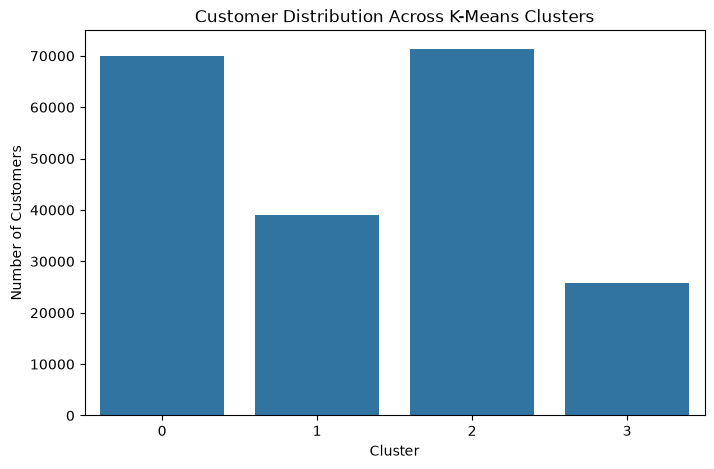

In [21]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=customer_df,
    x="KMeans_Cluster"
)

plt.title("Customer Distribution Across K-Means Clusters")
plt.xlabel("Cluster")
plt.ylabel("Number of Customers")

plt.show()